# 03_4 · Đánh giá cuối trên tập test, phân tích và lưu mô hình
**Phần 4/4.** Dùng cấu hình đã chọn ở 03_3, huấn luyện lại với dữ liệu đến 30/11 và đánh giá trên tháng 12 **một lần duy nhất**. Sau đó kiểm định chênh lệch, phân tích thêm, xem ví dụ cụ thể và lưu mô hình triển khai.

**Đầu ra:** `reports/recsys_ket_qua_test.csv`, `reports/figs/R1_so_sanh_mo_hinh.png`, `models/recsys_final.pkl`.

In [1]:
from recsys_lib import *
from IPython.display import display

inter, item_stats, catalog, n_inv_total = load_cache()
st = load_state(); blacklist = set(st["blacklist"])
print(f"{len(inter):,} dòng | loại {len(blacklist)} mã không phải hàng hóa")
best = pd.Series({"mo_hinh": st["best_config"]}); cold_best = st["cold_choice"]
val = Split(inter, catalog, blacklist, *VAL)

Latent model: SVD (scikit-learn)
350,663 dòng | loại 34 mã không phải hàng hóa


## 7. Đánh giá cuối trên tập test (tháng 12) — chạy một lần
Tham số cố định theo kết quả validation; huấn luyện lại với dữ liệu đến 30/11.

In [2]:
test = Split(inter, catalog, blacklist, *TEST); print(test.summary())
print("Cấu hình:", best.mo_hinh, "| khách mới dùng:", cold_best)
cold_model_t = make_cold(cold_best, test)
final_model = rebuild(best.mo_hinh, test); pop_t = Popularity(30).fit(test)
test_res = {}
entries = [("Baseline: bán chạy 30 ngày (người mua)", pop_t, pop_t),
           ("Bán chạy theo giới tính", SegmentPopularity(30, 0.7).fit(test), cold_model_t),
           (f"Mô hình tốt nhất: {best.mo_hinh}", final_model, cold_model_t)]
frames = []
for name, mdl, cm in entries:
    r = evaluate(test, make_scorer(mdl, cm)); test_res[name] = r; frames.append(summarize(r, name))
final_tab = pd.concat(frames)
final_tab.to_csv(REPORTS / "recsys_ket_qua_test.csv", index=False)
final_tab[final_tab.nhom.isin(["tat_ca", "co_lich_su", "khach_moi"])][["mo_hinh", "nhom", "so_khach", f"recall@{K}", f"ndcg@{K}", f"map@{K}", f"hit_rate@{K}", "coverage", "da_dang_nganh"]]

train < 01/12/2025: 239,461 dòng, 62,329 khách | mẫu được gợi ý: 1,594 | khách kỳ đánh giá: 7,904 (có lịch sử 2,926, mới 4,978) | trần Recall: 0.806
Cấu hình: SegmentPop | khách mới dùng: Popularity14


,mo_hinh,nhom,so_khach,recall@10,ndcg@10,map@10,hit_rate@10,coverage,da_dang_nganh
0,Baseline: bán chạy 30 ngày (người mua),tat_ca,7904,0.0541,0.0333,0.0180,0.1261,0.0132,3.9978
1,Baseline: bán chạy 30 ngày (người mua),co_lich_su,2926,0.0433,0.0283,0.0143,0.1241,0.0132,3.9942
2,Baseline: bán chạy 30 ngày (người mua),khach_moi,4978,0.0604,0.0362,0.0201,0.1274,0.0132,4.0000
0,Bán chạy theo giới tính,tat_ca,7904,0.0557,0.0354,0.0197,0.1308,0.0207,3.9198
1,Bán chạy theo giới tính,co_lich_su,2926,0.0477,0.0341,0.0189,0.1367,0.0207,3.7833
2,Bán chạy theo giới tính,khach_moi,4978,0.0604,0.0362,0.0201,0.1274,0.0207,4.0000
0,Mô hình tốt nhất: SegmentPop,tat_ca,7904,0.0557,0.0354,0.0197,0.1308,0.0207,3.9198
1,Mô hình tốt nhất: SegmentPop,co_lich_su,2926,0.0477,0.0341,0.0189,0.1367,0.0207,3.7833
2,Mô hình tốt nhất: SegmentPop,khach_moi,4978,0.0604,0.0362,0.0201,0.1274,0.0207,4.0000


In [3]:
# Chênh lệch so với baseline có ý nghĩa không? (bootstrap ghép cặp, 95%)
names = list(test_res); b0, b1 = test_res[names[0]], test_res[names[-1]]
for g, mask in [("co_lich_su", test.known), ("khach_moi", ~test.known), ("tat_ca", np.ones(len(test.known), bool))]:
    for metric in ["ndcg", "recall"]:
        d, lo, hi = paired_bootstrap(getattr(b1, metric)[mask], getattr(b0, metric)[mask])
        print(f"{g:11s} {metric:6s}@{K}: mô hình tốt nhất − baseline = {d:+.4f} (95% CI {lo:+.4f} đến {hi:+.4f})",
              "→ khác biệt có ý nghĩa" if lo > 0 or hi < 0 else "→ chưa khác biệt rõ ràng")
print(f"\nTrần Recall (mẫu còn bán ở kỳ test): {test.ceiling:.3f}")

co_lich_su  ndcg  @10: mô hình tốt nhất − baseline = +0.0058 (95% CI +0.0034 đến +0.0081) → khác biệt có ý nghĩa
co_lich_su  recall@10: mô hình tốt nhất − baseline = +0.0045 (95% CI +0.0007 đến +0.0083) → khác biệt có ý nghĩa
khach_moi   ndcg  @10: mô hình tốt nhất − baseline = +0.0000 (95% CI +0.0000 đến +0.0000) → chưa khác biệt rõ ràng
khach_moi   recall@10: mô hình tốt nhất − baseline = +0.0000 (95% CI +0.0000 đến +0.0000) → chưa khác biệt rõ ràng
tat_ca      ndcg  @10: mô hình tốt nhất − baseline = +0.0021 (95% CI +0.0013 đến +0.0030) → khác biệt có ý nghĩa
tat_ca      recall@10: mô hình tốt nhất − baseline = +0.0017 (95% CI +0.0004 đến +0.0031) → khác biệt có ý nghĩa

Trần Recall (mẫu còn bán ở kỳ test): 0.806


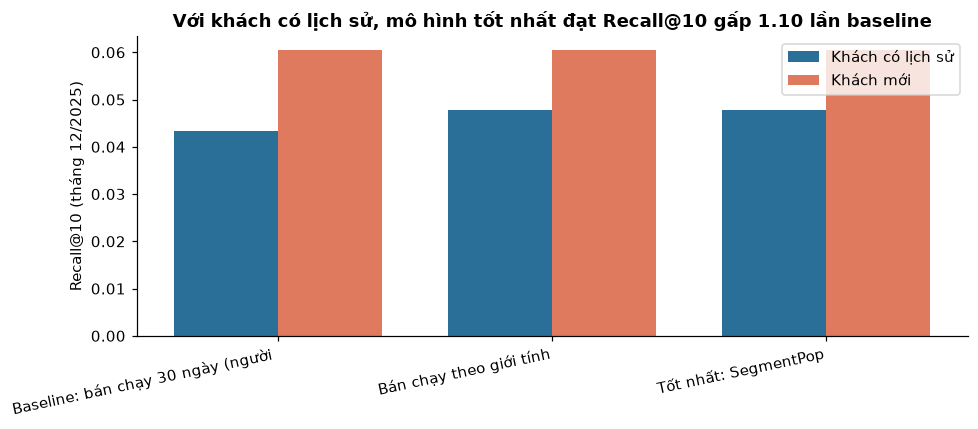

In [4]:
# Biểu đồ so sánh mô hình trên tập test
plot = final_tab[final_tab.nhom.isin(["co_lich_su", "khach_moi"])].pivot(index="mo_hinh", columns="nhom", values=f"recall@{K}").loc[[e[0] for e in entries]]
fig, ax = plt.subplots(figsize=(9, 4)); x = np.arange(len(plot)); wd = 0.38
ax.bar(x - wd/2, plot["co_lich_su"], wd, label="Khách có lịch sử", color="#2a6f97")
ax.bar(x + wd/2, plot["khach_moi"], wd, label="Khách mới", color="#e07a5f")
ax.set_xticks(x); ax.set_xticklabels([n.replace("Mô hình tốt nhất: ", "Tốt nhất: ")[:34] for n in plot.index], rotation=12, ha="right")
gain = plot["co_lich_su"].iloc[-1] / max(plot["co_lich_su"].iloc[0], 1e-9)
ax.set_title(f"Với khách có lịch sử, mô hình tốt nhất đạt Recall@{K} gấp {gain:.2f} lần baseline"); ax.set_ylabel(f"Recall@{K} (tháng 12/2025)")
ax.legend(); plt.savefig(FIGS / "R1_so_sanh_mo_hinh.png", dpi=160, bbox_inches="tight"); plt.show()

## 8. Phân tích thêm (trên validation, không dùng test)

In [5]:
# (a) Có nên loại mẫu đã mua khỏi gợi ý? (b) Cửa sổ "mẫu còn bán" 30/60/90 ngày ảnh hưởng thế nào?
rows = []
mdl = rebuild(best.mo_hinh, val); first60 = FirstTimer(60).fit(val)
for ex in [True, False]:
    r = evaluate(val, make_scorer(mdl, first60), exclude_seen=ex)
    d = summarize(r, f"{best.mo_hinh} | loại mẫu đã mua={ex}"); rows.append(d[d.nhom == "co_lich_su"])
for days in [30, 60, 90]:
    sp_ = Split(inter, catalog, blacklist, *VAL, active_days=days)
    m = rebuild(best.mo_hinh, sp_); r = evaluate(sp_, make_scorer(m, FirstTimer(60).fit(sp_)))
    d = summarize(r, f"{best.mo_hinh} | cửa sổ mẫu còn bán={days} ngày", {"tran_recall": sp_.ceiling}); rows.append(d[d.nhom == "co_lich_su"])
pd.concat(rows)[["mo_hinh", f"recall@{K}", f"ndcg@{K}", "coverage", "tran_recall"]]

,mo_hinh,recall@10,ndcg@10,coverage,tran_recall
1,SegmentPop | loại mẫu đã mua=True,0.0581,0.0375,0.0217,NaN
1,SegmentPop | loại mẫu đã mua=False,0.0605,0.0414,0.0175,NaN
1,SegmentPop | cửa sổ mẫu còn bán=30 ngày,0.0581,0.0375,0.0262,0.8601
1,SegmentPop | cửa sổ mẫu còn bán=60 ngày,0.0581,0.0375,0.0217,0.8762
1,SegmentPop | cửa sổ mẫu còn bán=90 ngày,0.0581,0.0375,0.0192,0.8818


In [6]:
# Ví dụ gợi ý cụ thể cho một khách có lịch sử trong tập test (kiểm tra bằng mắt có hợp lý không)
i = int(np.where(test.known2)[0][0]); u = test.eval_users[i]
bought = test.train[test.train.customer_id == u].sort_values("ngay").tail(5)
print("Khách", u, "đã mua gần đây:"); display(bought.assign(ten=bought.item.map(dict(zip(catalog.item, catalog.product_name))))[["ngay", "item", "ten"]])
sc = make_scorer(final_model, cold_model_t)(test.rows[i:i+1])[0]
sc = np.where(test.seen[test.rows[i]].toarray().ravel() > 0, -1e9, sc); top = np.argsort(-sc)[:K]
print("Gợi ý top-10:"); display(pd.DataFrame({"item": test.items[top], "ten": test.name[top], "nganh": test.group[top]}))
print("Thực tế khách mua trong tháng 12:", sorted(set(inter[(inter.customer_id == u) & (inter.ngay >= test.start)].item)))

Khách C_0010657d21c204b7 đã mua gần đây:


,ngay,item,ten
104,2025-09-14,96003925,Bộ thun ngắn tay bé gái - 960.039
95,2025-09-16,33036,Set 2 quần lót BG 33.036
96,2025-09-16,92778000,Áo khoác nỉ BT 92.778
98,2025-09-16,95008825,Đầm thô ngắn tay bé gái - 950.088
101,2025-09-16,95010525,Đầm ngắn tay bé gái - 950.105


Gợi ý top-10:


,item,ten,nganh
0,95206025,Đầm sát nách bé gái - 952.060,03. Dress (đầm & yếm)
1,95600425,Yếm váy bé gái - 956.004,03. Dress (đầm & yếm)
2,95900125,Bộ ngắn tay bé gái - 959.001,04. Set (bộ)
3,95010925,Đầm ngắn tay voan bé gái - 950.109,03. Dress (đầm & yếm)
4,96600625,Bộ dài tay nỉ bé gái - 966.006,04. Set (bộ)
5,95009625,Váy ngắn tay bé gái - 950.096,03. Dress (đầm & yếm)
6,95205725,Đầm sát nách thô bé gái - 952.057,03. Dress (đầm & yếm)
7,95503825,Chân váy thô bé gái - 955.038,02. Bottom (quần & chân váy)
8,91002925,Áo dài tay thun trẻ em - 910.029,01. Top (áo)
9,68302325,Giày búp bê bé gái - 683.023,05. Footwear


Thực tế khách mua trong tháng 12: ['20001000', '95010325', '95102125']


## 9. Lưu mô hình và hàm gợi ý
Mô hình dùng để triển khai được huấn luyện lại trên **toàn bộ dữ liệu 2025** (không còn tập kiểm tra).

In [7]:
deploy = Split(inter, catalog, blacklist, "2026-01-01", "2026-02-01")
dep_model = rebuild(best.mo_hinh, deploy); dep_cold = FirstTimer(60).fit(deploy)
dep_scorer = make_scorer(dep_model, dep_cold)

def recommend(customer_id, k=K, exclude_seen=True):
    # Gợi ý top-k mẫu cho khách; khách chưa có lịch sử nhận gợi ý của khách mới
    row = deploy.user_idx.get(str(customer_id), -1)
    s = dep_scorer(np.array([row]))[0].copy()
    if exclude_seen and row >= 0:
        s[deploy.seen[row].toarray().ravel() > 0] = -1e9
    top = np.argsort(-s)[:k]
    return pd.DataFrame({"item": deploy.items[top], "ten_san_pham": deploy.name[top], "nganh_hang": deploy.group[top], "diem": s[top]})

with open(MODELS / "recsys_final.pkl", "wb") as f:
    pickle.dump({"cau_hinh": best.mo_hinh, "items": deploy.items, "users": deploy.users,
                 "blacklist": sorted(blacklist), "k": K}, f)
recommend(deploy.users[0])

,item,ten_san_pham,nganh_hang,diem
0,37100425,Mũ bé gái -371.004,06. Others,1.0000
1,63500925,Quần lót bé gái - 635.009,06. Others,0.6821
2,95303825,Đầm sát nách bé gái - 953.038,03. Dress (đầm & yếm),0.5371
3,91603625,Bộ áo dài tết bé gái - 916.036,04. Set (bộ),0.5335
4,90016925,Áo ngắn tay thun bé gái - 900.169,01. Top (áo),0.5016
5,95600425,Yếm váy bé gái - 956.004,03. Dress (đầm & yếm),0.4530
6,95207125,Đầm sát nách dạ bé gái - 952.071,03. Dress (đầm & yếm),0.4393
7,90017425,Áo ngắn tay thun bé gái - 900.174,01. Top (áo),0.4183
8,37100525,Mũ bé trai -371.005,06. Others,0.3904
9,95504425,Chân váy nhung bé gái - 955.044,02. Bottom (quần & chân váy),0.3675


## Việc cần làm sau khi chạy xong cả 4 phần
1. Điền kết quả vào báo cáo: bảng baseline (03_2), bảng validation (03_3), bảng test và khoảng tin cậy (03_4), biểu đồ `R1_so_sanh_mo_hinh.png`.
2. Viết phân tích lỗi: mô hình hơn baseline bao nhiêu với khách có lịch sử, vì sao khách mới chỉ dùng được độ phổ biến, trần Recall nói gì.
3. Gửi tôi các file CSV trong `reports/recsys_*.csv` để tôi giúp viết phần kết quả và thảo luận.